## Imports

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from collections import Counter
import sys
from pathlib import Path
from types import SimpleNamespace
import matplotlib.colors as mcolors
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
from scipy.stats import gaussian_kde
import math
from matplotlib.backends.backend_pdf import PdfPages

# Add the parent of mixture_density_network to sys.path
project_root = Path().absolute().parent  # points to Madidi_forest_analysis
sys.path.append(str(project_root))
print("Added to sys.path:", project_root)
from mixture_density_network.src.blocks import MixtureDensityNetwork, NoiseType
from mixture_density_network.training.train import LitModel

Added to sys.path: /stor/work/Wilke/kelly/Madidi_forest_analysis


/stor/work/Wilke/kelly/Madidi_forest_analysis/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/stor/work/Wilke/kelly/Madidi_forest_analysis/.venv/lib/python3.11/site-packages/lightning_fabric/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__("pkg_resources").declare_namespace(__name__)


## Device Configuration

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
device

device(type='cpu')

## Load Data and Model

In [3]:
interests = ["DrySeasonDeficit", "ResinPi", "TotalP"]
dir_name = "batch32_epochs100_lr0.0004_weightdecay1e-06_beta10.9_beta20.95_dropout0.1_numcomponents5_hidden64_rarity4"

# Split by underscores
parts = dir_name.split("_")
# Extract parameters
params = {}
for part in parts:
    if part.startswith("batch"):
        params["batch_size"] = int(part.replace("batch", ""))
    elif part.startswith("epochs"):
        params["epochs"] = int(part.replace("epochs", ""))
    elif part.startswith("lr"):
        params["learn_rate"] = float(part.replace("lr", ""))
    elif part.startswith("weightdecay"):
        params["weight_decay"] = float(part.replace("weightdecay", ""))
    elif part.startswith("beta1"):
        params["beta1"] = float(part.replace("beta1", ""))
    elif part.startswith("beta2"):
        params["beta2"] = float(part.replace("beta2", ""))
    elif part.startswith("dropout"):
        params["dropout"] = float(part.replace("dropout", ""))
    elif part.startswith("numcomponents"):
        params["num_components"] = int(part.replace("numcomponents", ""))
    elif part.startswith("hidden"):
        params["hidden_size"] = int(part.replace("hidden", ""))
    elif part.startswith("rarity"):
        params["rarity_threshold"] = int(part.replace("rarity", ""))
        
# Default rarity_threshold to None if not found
params["rarity_threshold"] = params.get("rarity_threshold", None)

print(params)

{'batch_size': 32, 'epochs': 100, 'learn_rate': 0.0004, 'weight_decay': 1e-06, 'beta1': 0.9, 'beta2': 0.95, 'dropout': 0.1, 'num_components': 5, 'hidden_size': 64, 'rarity_threshold': 4}


In [4]:
interests_data = {}

for interest in interests:    
    # Define directories
    data_dir = Path(f"../output/Panama/{interest}/{dir_name}")
    output_dir = Path(f"figures/Panama/{interest}/{dir_name}")
    output_dir.mkdir(parents=True, exist_ok=True)

    # Pick the checkpoint with the lowest val_loss (most negative)
    checkpoint_files = list((data_dir / "checkpoints").glob("checkpoint_epoch=*_val_loss=*.ckpt"))
    best_checkpoint = min(checkpoint_files, key=lambda p: float(p.name.split("val_loss=")[-1].replace(".ckpt","")))

    # Extract best epoch 
    best_epoch = int(best_checkpoint.name.split("checkpoint_epoch=")[1].split("_")[0])
    print(f"Best epoch for {interest}: {best_epoch}")

    # Load dataset
    rarity_suffix = f"_rarity{params['rarity_threshold']}" if params["rarity_threshold"] else ""
    dataset_path = Path(f"../data/metadata/panama/dataset_{interest}{rarity_suffix}.pt")
    dataset = torch.load(dataset_path)
    X_train = dataset["train"]["embedding"].to(device)
    y_train = dataset["train"][interest].to(device)
    X_val = dataset["val"]["embedding"].to(device)
    y_val = dataset["val"][interest].to(device)
    X_test = dataset["test"]["embedding"].to(device)
    y_test = dataset["test"][interest].to(device)

    # Build train/test DataFrames 
    train_df = pd.DataFrame({
        'FEATURE_ID': dataset['train']['FEATURE_ID'],
        interest: dataset['train'][interest].cpu().numpy(),
        'embedding': list(dataset['train']['embedding'].cpu().numpy())
    })

    test_df = pd.DataFrame({
        'FEATURE_ID': dataset['test']['FEATURE_ID'],
        interest: dataset['test'][interest].cpu().numpy(),
        'embedding': list(dataset['test']['embedding'].cpu().numpy())
    })

    # Load model
    args = SimpleNamespace(
        data_file=str(dataset_path),
        lr=params["learn_rate"],
        weight_decay=params["weight_decay"],
        batch_size=params["batch_size"],
        epochs=params["epochs"],
        beta1=params["beta1"],
        beta2=params["beta2"],
        dropout=params["dropout"],
        num_components=params["num_components"],
        hidden_dim=params["hidden_size"],
    )
    model_module = LitModel.load_from_checkpoint(checkpoint_path=str(best_checkpoint), args=args, map_location=device,)
    model = model_module.model.to(device)
    model.eval()

    # Generate predictions
    with torch.no_grad():
        y_hat = model.sample(X_test)

    # Reverse normalization
    y_mean = torch.tensor(train_df[interest].values, dtype=torch.float32).mean().item()
    y_std = torch.tensor(train_df[interest].values, dtype=torch.float32).std().item()
    y_hat_unnormalized = y_hat * y_std + y_mean
    y_test_unsq = y_test.unsqueeze(1)

    # Rarity distribution
    all_splits = []
    for split in ['train', 'val', 'test']:
        df_split = pd.DataFrame({'FEATURE_ID': dataset[split]['FEATURE_ID'].numpy()})
        all_splits.append(df_split)
    all_df = pd.concat(all_splits, ignore_index=True)
    feature_counts = all_df['FEATURE_ID'].value_counts().reset_index()
    feature_counts.columns = ['FEATURE_ID', 'num_plots']
    rarity_threshold = 4
    feature_counts['rarity'] = ['Rare' if n <= rarity_threshold else 'Majority' for n in feature_counts['num_plots']]

    # Store everything
    interests_data[interest] = {
        "dataset": dataset,
        "best_epoch": best_epoch,
        "train_df": train_df,
        "test_df": test_df,
        "X_test": X_test,
        "y_test": y_test_unsq,
        "y_hat": y_hat_unnormalized,
        "feature_counts": feature_counts,
        "output_dir": output_dir
    }

Best epoch for DrySeasonDeficit: 5
Best epoch for ResinPi: 9
Best epoch for TotalP: 10


In [5]:
normal_names = {
    "DrySeasonDeficit": "Dry-Season Moisture",
    "ResinPi": "Resin Phosphorus",
    "TotalP": "Total Phosphorus",
}

In [6]:
def darken_color(color, amount=0.4):
    """
    Darken the given color by multiplying (1-luminosity) by amount
    """
    c = mcolors.to_rgb(color)
    return tuple(max(min(comp * amount, 1), 0)for comp in c)

## Plot Loss

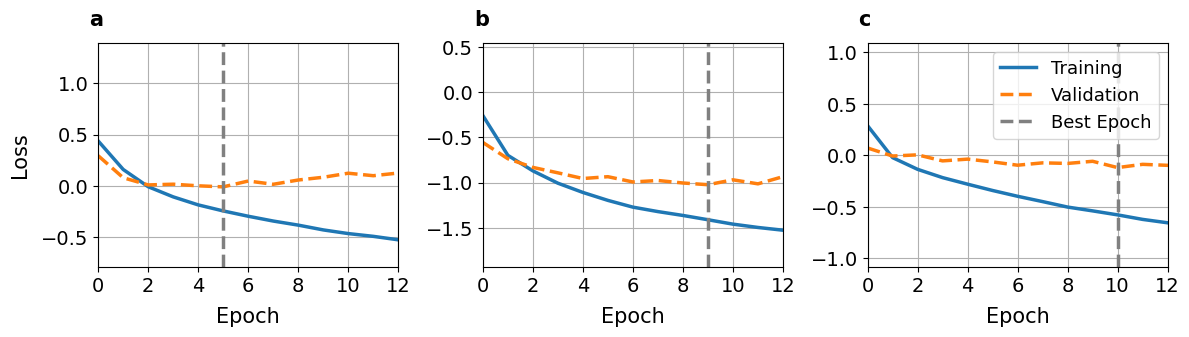

: 

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes = axes.flatten()
labels = ['a', 'b', 'c']

for ax, (interest, data), label in zip(axes, interests_data.items(), labels):
    output_dir = data["output_dir"]
    data_dir = Path(f"../output/Panama/{interest}/{dir_name}")

    metrics_csv = data_dir / "training/version_0/metrics.csv"
    metrics = pd.read_csv(metrics_csv)

    train_losses = metrics[['epoch', 'train_loss']].dropna().sort_values('epoch')
    val_losses = metrics[['epoch', 'val_loss']].dropna().sort_values('epoch')

    epochs = train_losses['epoch'].values
    ax.plot(epochs, train_losses['train_loss'], label='Training', color='tab:blue', linewidth=2.5)
    ax.plot(epochs, val_losses['val_loss'], label='Validation', color='tab:orange', linestyle='--', linewidth=2.5)

    ax.tick_params(labelsize=14)
    ax.grid(True)

    # Add vertical line at best epoch
    ax.axvline(data["best_epoch"], color='gray', linestyle='--', label='Best Epoch', linewidth=2.5)

    # Set x-axis a bit beyond the best checkpoint epoch
    buffer = 2  # extra epochs past best
    ax.set_xlim(left=0, right=data["best_epoch"] + buffer)

    # Expand y-limits to leave space for legend
    y_max = max(train_losses['train_loss'].max(), val_losses['val_loss'].max())
    y_min = min(train_losses['train_loss'].min(), val_losses['val_loss'].min())
    ax.set_ylim(y_min, y_max + 0.8)

    ax.set_xlabel('Epoch', fontsize=15, labelpad=8)

    # Only show y-label on the first subplot
    if ax == axes[0]:
        ax.set_ylabel('Loss', fontsize=15, labelpad=8)

    # Only show legend on the last subplot
    if ax == axes[-1]:
        ax.legend(fontsize=13, loc='upper right')

    # Add letter labels
    ax.annotate(f"{label}", xy=(-0.03, 1.06), xycoords='axes fraction', fontsize=15, fontweight='bold', va='bottom', ha='left')

# Define consistent x-ticks starting at 0
x_min = 0
x_max = max(ax.get_xlim()[1] for ax in axes)  
x_ticks = np.arange(x_min, x_max + 1, step=2)  
for ax in axes:
    ax.set_xticks(x_ticks)

plt.tight_layout()  
plt.savefig("figures/Panama/final/combined_loss_rarity.pdf", dpi=300)
plt.show()

## Plot Distribution + Model's Recreation

one prediction per row = a feature that occurs 5 times gets 5 predictions

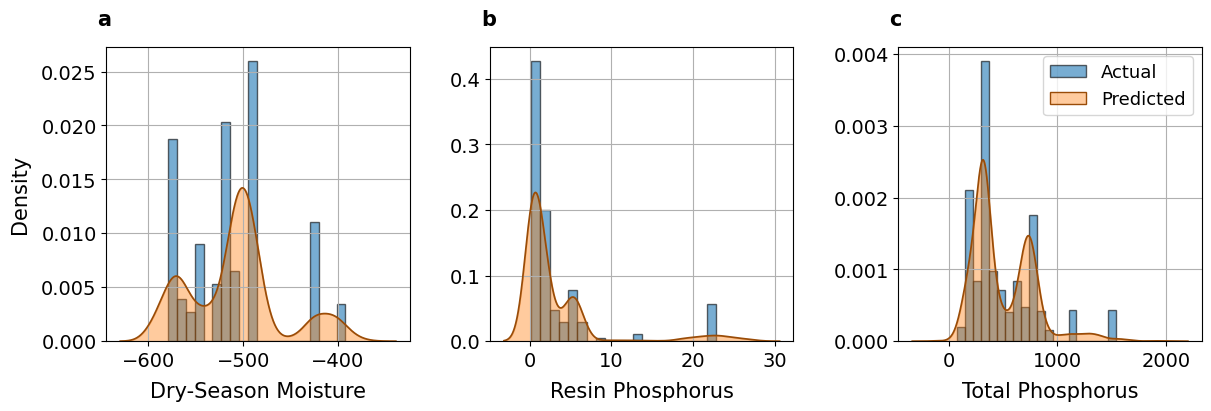

: 

In [ ]:
labels = ["a", "b", "c"]
num_interests = len(interests_data)

fig, axes = plt.subplots(
    1, num_interests,
    figsize=(12, 4),
    constrained_layout=True,
    gridspec_kw={'wspace': 0.1}
)

if num_interests == 1:
    axes = [axes]

for i, (ax, (interest, data), label) in enumerate(zip(axes, interests_data.items(), labels)):
    y_test = data["y_test"]
    y_hat = data["y_hat"]

    actual = y_test[:, 0].cpu().numpy()
    predicted = y_hat[:, 0].cpu().numpy()

    # Histogram
    ax.hist(actual, bins=20, alpha=0.6, label='Actual', density=True, color='tab:blue', edgecolor='black')

    # KDE 
    kde = gaussian_kde(predicted)
    x_margin = (predicted.max() - predicted.min()) * 0.10 
    x_vals = np.linspace(predicted.min() - x_margin, predicted.max() + x_margin, 1000)
    kde_vals = kde(x_vals)
    ax.fill_between(x_vals, kde_vals, color=mcolors.to_rgba('tab:orange', 0.4))
    ax.plot(x_vals, kde_vals, color=darken_color('tab:orange', amount=0.6), linewidth=1.25)

    ax.set_xlabel(normal_names.get(interest, interest), fontsize=15, labelpad=8)
    ax.set_ylabel('Density', fontsize=15, labelpad=8)
    ax.tick_params(axis='both', labelsize=14)
    ax.grid(True)

    # Only show y-label on the first subplot
    if i != 0:
        ax.set_ylabel('')

    # Only show legend on the last subplot
    if i == (num_interests - 1):
        kde_proxy = mpatches.Patch(facecolor=mcolors.to_rgba('tab:orange', 0.4), edgecolor=darken_color('tab:orange', amount=0.6), label='Predicted')
        handles, labels = ax.get_legend_handles_labels()
        handles.append(kde_proxy)
        ax.legend(handles=handles, fontsize=13, loc='upper right')

    # Add letter labels
    ax.annotate(f"{label}", xy=(-0.03, 1.06), xycoords='axes fraction', fontsize=15, fontweight='bold', va='bottom', ha='left')

plt.savefig("figures/Panama/final/combined_distribution_rarity.pdf", dpi=300)
plt.show()

## Plot Model Predictions

In [7]:
def generate_predictions(embedding, num_samples):
    """Generate predicted samples of the target variable for a given embedding."""
    
    embedding_tensor = torch.tensor(embedding, dtype=torch.float32).unsqueeze(0).repeat(num_samples, 1).to(device)
    with torch.no_grad():
        predictions = model.sample(embedding_tensor).cpu().numpy()
    return pd.DataFrame(predictions, columns=[interest])

In [8]:
# Plotting for each feature
def plot_feature_actual_vs_predicted(test_df, train_df, feature_id, num_samples, ax, xmin, xmax, ymax):
    """Plot actual values as vertical lines with horizontal jitter for duplicates,
    and KDE of predictions for a single FEATURE_ID."""
    
    # Filter df_combined to only include rows of the specified FEATURE_ID
    feature_data = test_df[test_df['FEATURE_ID'] == feature_id]
    
    # Extract the actual values of the interest variable and the embedding
    actual_values = feature_data[interest].values
    embedding = feature_data['embedding'].iloc[0]

    # Generate predictions
    predictions = generate_predictions(embedding, num_samples)

    # Unnormalize predictions
    y_mean = torch.tensor(train_df[interest].values, dtype=torch.float32).mean().item()
    y_std = torch.tensor(train_df[interest].values, dtype=torch.float32).std().item()
    predictions[interest] = predictions[interest] * y_std + y_mean
    pred_vals = predictions[interest].values

    # Rug for actual values
    jitter = (np.random.rand(len(actual_values)) - 0.5) * 0.01
    sns.rugplot(actual_values + jitter, ax=ax, color='tab:blue', linewidth=2.5, height=1, zorder=1)

    # KDE for predicted values
    x_vals = np.linspace(xmin, xmax, 500)
    kde = gaussian_kde(pred_vals)
    kde_vals = kde(x_vals)

    ax.fill_between(x_vals, kde_vals, color='tab:orange', alpha=0.4, zorder=2)
    ax.plot(x_vals, kde_vals, color=darken_color('tab:orange', amount=0.5), linewidth=1, zorder=2)

    # Set y-axis based on actual KDE values
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(0, ymax)

    # Labels, title, and styling
    ax.set_xlabel(normal_names.get(interest, interest), fontsize=15, labelpad=8)
    ax.set_ylabel('Density', fontsize=15, labelpad=8)
    ax.set_title(f'Feature ID {feature_id}', fontsize=14)
    ax.tick_params(axis='both', labelsize=14)
    ax.grid(True)

    # Only show legend in the top right plot
    if ax.get_subplotspec().rowspan.start == 0 and ax.get_subplotspec().colspan.start == 2:
        rug_proxy = mlines.Line2D([], [], color='tab:blue', linewidth=2.5, linestyle='-', label='Actual')
        kde_proxy = mpatches.Patch(facecolor=mcolors.to_rgba('tab:orange', 0.4), edgecolor=darken_color('tab:orange', amount=0.6), label='Predicted')
        handles, labels = ax.get_legend_handles_labels()
        handles.append(rug_proxy)
        handles.append(kde_proxy)
        ax.legend(handles=handles, fontsize=13)

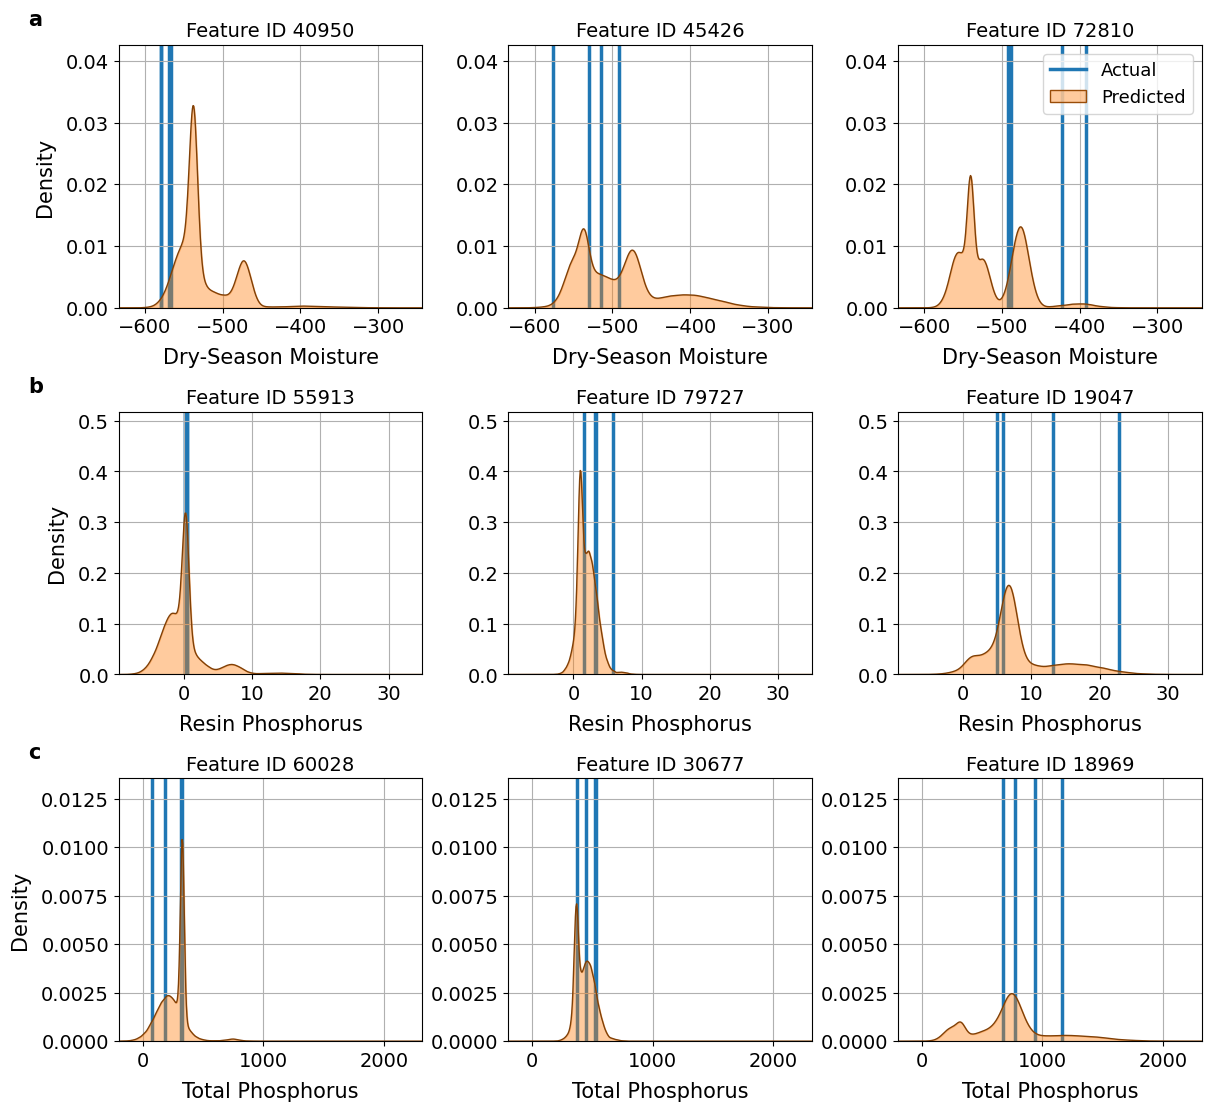

In [27]:
# Define the specific features for each interest
specific_features_per_interest = {
    "DrySeasonDeficit": ["40950", "45426", "72810"],
    "ResinPi": ["55913", "79727", "19047"],
    "TotalP": ["60028", "30677", "18969"],
}

num_features_per_interest = 3  # 3 features per interest
interests = list(interests_data.keys())
num_interests = len(interests)

fig, axes = plt.subplots(num_interests, num_features_per_interest, figsize=(12, 11), constrained_layout=True)

# Share x and y axes per row
for r in range(num_interests):
    for c in range(1, num_features_per_interest):
        axes[r, c].sharex(axes[r, 0])
        axes[r, c].sharey(axes[r, 0])

for row, interest in enumerate(interests):
    data = interests_data[interest]
    test_df = data["test_df"]
    train_df = data["train_df"]

    # Select 3 random features from the top value_count
    # max_value_count = test_df['FEATURE_ID'].value_counts().max()
    # filtered_test_df = test_df[test_df.groupby('FEATURE_ID')['FEATURE_ID'].transform('count') == test_df['FEATURE_ID'].value_counts().max()]
    # random_features = filtered_test_df['FEATURE_ID'].sample(3).unique()

    # Select specific features
    selected_features = specific_features_per_interest[interest]
    selected_features = [int(f) for f in specific_features_per_interest[interest]]

    # Collect all actual and predicted values for shared x-axis limits
    all_actual = []
    all_pred = []
    all_kde_max = []

    for feature_id in selected_features:
        fdata = test_df[test_df["FEATURE_ID"] == feature_id]

        # Actual
        actual_vals = fdata[interest].values
        all_actual.append(actual_vals)

        # Predicted
        embedding = fdata["embedding"].iloc[0]
        preds = generate_predictions(embedding, num_samples=100000)

        # Unnormalize
        y_mean = train_df[interest].mean()
        y_std = train_df[interest].std()
        preds[interest] = preds[interest] * y_std + y_mean

        all_pred.append(preds[interest].values)

    # Flatten lists into vectors
    all_actual = np.concatenate(all_actual)
    all_pred = np.concatenate(all_pred)

    # Shared x range
    row_xmin = min(all_actual.min(), all_pred.min())
    row_xmax = max(all_actual.max(), all_pred.max())

    # Compute shared y-limit for KDE across all 3 features
    for pred_vals in all_pred.reshape(num_features_per_interest, -1):
        kde = gaussian_kde(pred_vals)
        x_vals = np.linspace(row_xmin, row_xmax, 500)
        kde_max = kde(x_vals).max()
        all_kde_max.append(kde_max)

    row_ymax = max(all_kde_max) * 1.3

    for col, feature_id in enumerate(selected_features):
        ax = axes[row, col]
        plot_feature_actual_vs_predicted(test_df, train_df, feature_id, num_samples=100000, ax=ax, xmin=row_xmin, xmax=row_xmax, ymax=row_ymax)

        # Only show y-label on first column
        if col != 0:    
            ax.set_ylabel('')

# Add row letters (a, b, c) on the left of each row
row_letters = ["a", "b", "c"]
for row, letter in enumerate(row_letters):
    ax = axes[row, 0]  # first column
    ax.annotate(f"{letter}", xy=(-0.3, 1.06), xycoords='axes fraction', fontsize=15, fontweight='bold', va='bottom', ha='left')

plt.savefig(f"figures/Panama/final/actual_vs_predicted_3x3_random_rarity.pdf", dpi=300)
plt.show()

In [ ]:
# rows = 20
# cols = 10
# plots_per_page = rows * cols  
# sample = 100000

# for interest in interests_data:
#     data = interests_data[interest]
#     test_df = data["test_df"]
#     train_df = data["train_df"]

#     ## Compute number of pages

#     # Keep only features with exactly 4 actual observations
#     feature_counts = test_df.groupby("FEATURE_ID").size()
#     all_features = feature_counts[feature_counts == 4].index.to_numpy()

#     # Compute mean observed value per feature and sort
#     feature_means = test_df.groupby("FEATURE_ID")[interest].mean()
#     all_features = feature_means.loc[all_features].sort_values().index.to_numpy()

#     num_features = len(all_features)
#     num_pages = math.ceil(num_features / plots_per_page)
#     print(f"{interest}: {num_features} features = {num_pages} pages")

#     ## Compute global shared axes across all features for this interest
#     all_actual = []
#     all_pred = []

#     for feature_id in all_features:
#         fdata = test_df[test_df["FEATURE_ID"] == feature_id]

#         # Actual
#         actual_vals = fdata[interest].values
#         all_actual.append(actual_vals)

#         # Predicted
#         embedding = fdata["embedding"].iloc[0]
#         preds = generate_predictions(embedding, num_samples=sample)

#         y_mean = train_df[interest].mean()
#         y_std = train_df[interest].std()
#         preds[interest] = preds[interest] * y_std + y_mean

#         all_pred.append(preds[interest].values)

#     all_actual = np.concatenate(all_actual)
#     all_pred = np.concatenate(all_pred)

#     xmin = min(all_actual.min(), all_pred.min())
#     xmax = max(all_actual.max(), all_pred.max())
#     print(f"{interest}: global xmin={xmin:.3f}, xmax={xmax:.3f}")

#     # Shared y-limit across all features
#     x_vals = np.linspace(xmin, xmax, 500)
#     all_kde_max = []
#     for pred_vals in all_pred.reshape(len(all_features), -1):
#         kde = gaussian_kde(pred_vals)
#         all_kde_max.append(kde(x_vals).max())
#     # Average-based y-axis scaling instead of max-based
#     mean_peak = np.mean(all_kde_max)
#     # Add some padding
#     ymax = mean_peak * 1.3
#     print(f"{interest}: mean peak={mean_peak:.3f}, ymax={ymax:.3f}")

#     # Create PDF for all features
#     pdf_path = f"figures/Panama/final/all_features_{interest}_{sample}.pdf"
#     with PdfPages(pdf_path) as pdf:
#         # Loop over pages
#         for page in range(num_pages):
#             start = page * plots_per_page
#             end = min(start + plots_per_page, num_features)
#             page_features = all_features[start:end]

#             fig, axes = plt.subplots(rows, cols, figsize=(24, 44), constrained_layout=True)

#             # Share axes on page 
#             for r in range(rows):
#                 for c in range(cols):
#                     if r == 0 and c == 0:
#                         continue
#                     axes[r, c].sharex(axes[0, 0])
#                     axes[r, c].sharey(axes[0, 0])

#             axes = axes.flatten()

#             # Plot features on this page
#             for ax_idx, feature_id in enumerate(page_features):
#                 ax = axes[ax_idx]
#                 plot_feature_actual_vs_predicted(test_df, train_df, feature_id, num_samples=sample, ax=ax, xmin=xmin, xmax=xmax, ymax=ymax)
#                 ax.set_xlabel("")
#                 ax.set_ylabel("")
#                 if ax.get_legend() is not None:
#                     ax.get_legend().remove()

#             # Turn off empty axes
#             for ax_idx in range(len(page_features), len(axes)):
#                 axes[ax_idx].axis("off")

#             pdf.savefig(fig)
#             plt.close(fig)

DrySeasonDeficit: 304 features = 2 pages
DrySeasonDeficit: global xmin=-649.281, xmax=-200.199
DrySeasonDeficit: mean peak=0.024, ymax=0.032
ResinPi: 302 features = 2 pages
ResinPi: global xmin=-11.685, xmax=42.634
ResinPi: mean peak=0.207, ymax=0.269
TotalP: 306 features = 2 pages
TotalP: global xmin=-299.186, xmax=2492.161
TotalP: mean peak=0.004, ymax=0.005


## Make predictions about molecules outside of the dataset 
(From: https://www.sciencedirect.com/science/article/pii/S2666389923002490?via%3Dihub)